<a href="https://colab.research.google.com/github/janpeter19/BPL_YEAST_COB_Batch/blob/main/BPL_YEAST_COB_Batch_oms_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BPL_YEAST_COB_Batch script with OMSimulator

The key library OMSimulator is installed.

After the installation a small application BPL_YEAST_COB_Batch is loaded and run. You can continue with this example if you like.

In [1]:
!lsb_release -a # Actual VM Ubuntu version used by Google

No LSB modules are available.
Distributor ID:	Ubuntu
Description:	Ubuntu 24.04.5 LTS
Release:	24.04
Codename:	noble


In [2]:
!python --version

Python 3.13.18


In [3]:
%pip install -q uv

In [4]:
!uv pip install OMSimulator

Using Python 3.13.18 environment at: /usr
Resolved 7 packages in 297ms
Prepared 1 package in 3.87s
Installed 1 package in 2ms
 + omsimulator==3.0.0.post218


In [5]:
!uv pip install optlang

Using Python 3.13.18 environment at: /usr
Resolved 4 packages in 253ms
Prepared 2 packages in 100ms
Installed 2 packages in 3ms
 + optlang==1.9.1
 + swiglpk==5.0.13


In [6]:
!uv pip install --system git+https://github.com/janpeter19/FMU_explore.git

Using Python 3.13.18 environment at: /usr
Resolved 1 package in 387ms
Prepared 1 package in 2.11s
Installed 1 package in 0.86ms
 + fmu-explore==1.2.10 (from git+https://github.com/janpeter19/FMU_explore.git@c30b749422b2e0ef1dad927e7aa88df38654c6e4)


In [7]:
!uv pip install DyMat

Using Python 3.13.18 environment at: /usr
Resolved 1 package in 657ms
Prepared 1 package in 203ms
Installed 1 package in 0.98ms
 + dymat==0.7


# BPL_YEAST_COB_Batch setup


Now specific installation and the run simulations. Start with connecting to Github. Then upload the two files:

* FMU - BPL_YEAST_COB_Batch_linux_om_me.fmu
* Setup-file - BPL_YEAST_COB_Batch_oms.py
* Setup-file - BPL_YEAST_COB_Batch_oms_explore.py

In [43]:
%%bash
git clone https://github.com/janpeter19/BPL_YEAST_COB_Batch

Cloning into 'BPL_YEAST_COB_Batch'...


In [44]:
%cd BPL_YEAST_COB_Batch

/content/BPL_YEAST_COB_Batch/BPL_YEAST_COB_Batch/BPL_YEAST_COB_Batch


In [45]:
# Import the application model and context variables
from BPL_YEAST_COB_Batch_oms import*

In [46]:
# Import the general FMU_explore functions ana adapt them to the application
from fmu_explore_oms import AdaptWith

Application = AdaptWith(parValue, parLocation, parCheck,\
                        fmu_model, fmu_process_diagram, component_list_minimum,\
                        MSL_usage, MSL_version, BPL_version,\
                        options, simulationTime, timeDiscreteStates,\
                        diagrams, ax, lines)

par = Application.par
init = Application.init
simu = Application.simu
show = Application.show
disp = Application.disp

resetPen = Application.resetPen
process_diagram = Application.process_diagram
describe_general = Application.describe_general
describe_parts = Application.describe_parts
describe_MSL = Application.describe_MSL

FMU_explore_info = Application.FMU_explore_info
system_info = Application.system_info
SDG = Application.SDG

In [47]:
run -i BPL_YEAST_COB_Batch_oms_explore.py


Model for the process has been setup. Key commands:
 - par()       - change of parameters and initial values
 - init()      - change initial values only
 - simu()      - simulate and plot
 - newplot()   - make a new plot
 - show()      - show plot from previous simulation
 - disp()      - display parameters and initial values from the last simulation
 - describe()  - describe culture, broth, parameters, variables with values/units

Note that both disp() and describe() takes values from the last simulation
and the command process_diagram() brings up the main configuration

Brief information about a command by help(), eg help(simu)
Key system information is listed with the command system_info()


<Figure size 984.252x787.402 with 0 Axes>

In [48]:
%matplotlib inline
plt.rcParams['figure.figsize'] = [25/2.54, 20/2.54]

In [49]:
import warnings
warnings.filterwarnings("ignore")

## BPL_YEAST_COB_Batch - demo



In [50]:
from optlang import Model, Variable, Constraint, Objective

In [51]:
describe('process')

Batch cultivation of yeast


No processDiagram.png file in the FMU, but try the file on disk.


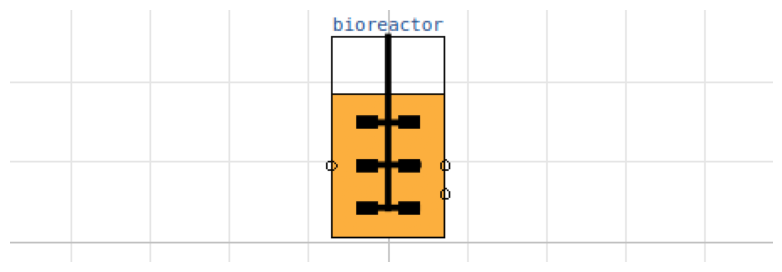

In [52]:
process_diagram()

In [53]:
describe('culture'); print(); #describe('liquidphase')                                  # Pump schedule parameter


Saccharomyces cerevisae - default parameters for strain H1022



In [54]:
# Define culture constraint-based model
def culture(G, E):

    # LP calculation of the optimal qGr, qEr based on G and E values

    # - parameters
    qO2max = 6.9e-3; kog = 2.3; koe = 1.6; YGr = 3.5; YEr = 1.32;
    alpha = 0.01; beta = 1.0

    # - transfer data from dynamic reactor model to static LP model
    qGr_opt = Variable('qGr_opt', lb=0)
    qEr_opt = Variable('qEr_opt', lb=0)

    # - LP model constraint and objective
    mu_max = Objective(YGr*qGr_opt + YEr*qEr_opt, direction='max')
    qO2lim = Constraint(kog*qGr_opt + koe*qEr_opt, ub=qO2max)
    qGlim = Constraint(qGr_opt, ub=alpha*max(0,G))
    qElim = Constraint(qEr_opt, ub=beta*max(0,E))

    # - put together the LP model
    yeast_model = Model(name='Yeast bottleneck model')
    yeast_model.objective = mu_max
    yeast_model.add(qO2lim)
    yeast_model.add(qGlim)
    yeast_model.add(qElim)

    # - do LP optimization
    yeast_model.optimize()

    return (yeast_model.objective.value, yeast_model.variables.qGr_opt.primal, yeast_model.variables.qEr_opt.primal, qO2lim.primal)

In [55]:
# Initialization
V_start=1.0
init(V_start=V_start, VX_start=V_start*2.0, VG_start=V_start*10, VE_start=V_start*3.0)

In [56]:
# Loop of simulations
t_final = 8.0
t_samp = 0.0333
n_samp = t_final/t_samp + 1

In [57]:
Application.fmu_model

'BPL_YEAST_COB.Batch_linux_2404_om_me.fmu'

In [58]:
t_samp

0.0333

MatReadError: Mat file appears to be truncated

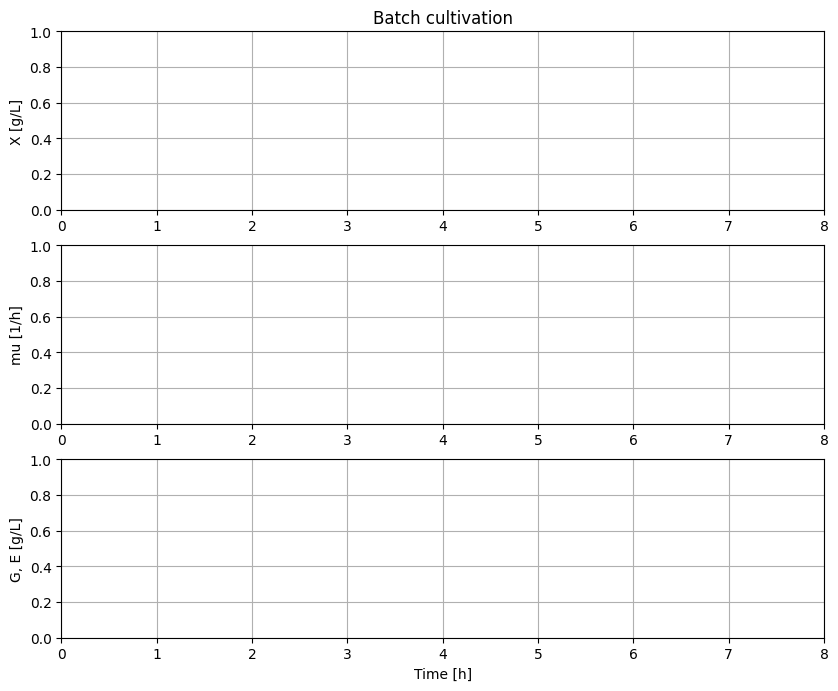

In [60]:
# Simulate n sample steps
newplot(title='Batch cultivation', plotType='TimeSeries2')
ax[0].set_xlim([0, t_final]); ax[1].set_xlim([0, t_final]); ax[2].set_xlim([0, t_final])

simu(t_samp, options = opts_fast)

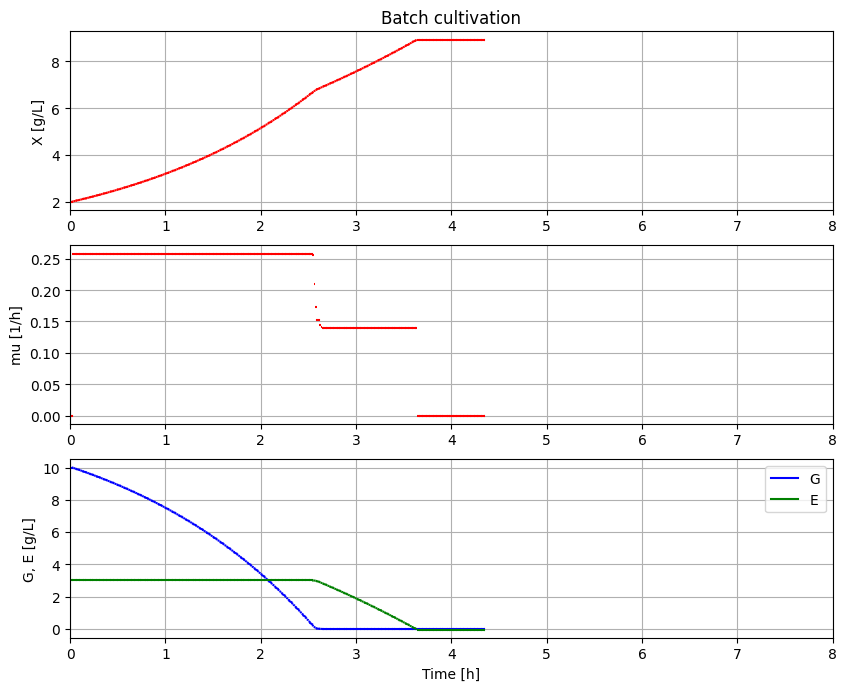

In [62]:
# Simulate n sample steps
newplot(title='Batch cultivation', plotType='TimeSeries2')
ax[0].set_xlim([0, t_final]); ax[1].set_xlim([0, t_final]); ax[2].set_xlim([0, t_final])

simu(t_samp)
for i in range(int(n_samp)):
    sim_res = Application.sim_res
    (mum_opt, qGr_opt, qEr_opt, qO2_opt) = culture(sim_res['Batch.bioreactor.c[2]'][-1], sim_res['Batch.bioreactor.c[3]'][-1])
    par(mum=mum_opt, qGr=qGr_opt, qEr=qEr_opt, qO2=qO2_opt)
    simu(t_samp, 'cont')

In [63]:
describe('MSL')

MSL: 4.1.0 - used components: none


In [64]:
system_info()


System information
 -OS: Linux
 -Python: 3.13.18
 -Scipy: 1.16.3
 -OMSimulator: 3.0.0.post218
 -FMU by: OpenModelica Compiler OpenModelica 1.26.0~dev-289-g6991cda
 -FMI: 2.0
 -Type: me
 -Name: BPL_YEAST_COB.Batch
 -Generated: 2025-09-01T06:03:44Z
 -MSL: 4.1.0
 -Description: Bioprocess Library version 2.3.2
 -Interaction: FMU_explore version 1.2.10


In [65]:
!pip show optlang|grep Version

Version: 1.9.1


In [ ]:
!lsb_release -d

In [ ]:
SDG()

In [42]:
Application.model.delete()